# Estimador de temperatura de fondo – Volve P-12 (versión corregida)
Objetivo: estimar `AVG_DOWNHOLE_TEMPERATURE` a partir de variables de superficie/producción, para poder reconstruirla cuando el sensor de fondo deja de funcionar (desde el 14-ene-2010).

Cambios frente al original: limpieza de ceros y picos del sensor, sin columna duplicada, sin variables que dependan del sensor de fondo, línea base, métricas, semilla fija y gráfico sin recortes.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
SEED = 42

In [ ]:
# Archivo local 
df = pd.read_csv('Volve_P-12_DatesCorrected_1.csv', index_col=0, parse_dates=True)
out = 'AVG_DOWNHOLE_TEMPERATURE'
print(df.shape, df.index.min().date(), df.index.max().date())

(3291, 14) 2007-01-09 2016-01-12


## 1. Calidad de datos
Temperatura = 0 significa *sin dato* (antes del arranque y tras la falla del sensor), no 0 °C. Además hay 7 días con valores físicamente imposibles (p. ej. 39.6 °C produciendo 5 000 bbl/d).

In [3]:
print('Días con T = 0:', (df[out]==0).sum())
print('Días con 0 < T < 100 (picos):', ((df[out]>0)&(df[out]<100)).sum())
print('Último dato válido:', df[df[out]>0].index.max().date())
# AVG_DP_TUBING = presión de fondo − WHP (identidad); tras 2010 queda igual a WHP
ok = df.AVG_DOWNHOLE_PRESSURE>0
print('Mediana |DHP − WHP − DP_TUBING| con sensor activo:', (df[ok].AVG_DOWNHOLE_PRESSURE-df[ok].AVG_WHP_P-df[ok].AVG_DP_TUBING).abs().median())

Días con T = 0: 2318
Días con 0 < T < 100 (picos): 7
Último dato válido: 2010-01-13
Mediana |DHP − WHP − DP_TUBING| con sensor activo: 2.842170943040401e-14


In [4]:
valid = df[(df[out]>=100)&(df[out]<=110)].copy()
print('Filas válidas:', len(valid))
print(valid.corr()[out].drop(out).sort_values().round(3))

Filas válidas: 966
DP_CHOKE_SIZE                    -0.538
AVG_WHP_P                        -0.339
AVG_DOWNHOLE_PRESSURE            -0.140
AVG_DP_TUBING                     0.158
BORE_GAS_VOL                      0.221
BORE_OIL_VOL                      0.240
BORE_WI_VOL                       0.423
onstreaminject_HRS                0.489
ON_STREAM_HRS                     0.527
BORE_WAT_VOL                      0.600
AVG_CHOKE_SIZE_P in percentage    0.735
AVG_WHT_P                         0.765
AVG_ANNULUS_PRESS                 0.792
Name: AVG_DOWNHOLE_TEMPERATURE, dtype: float64


## 2. Variables y partición cronológica
Solo variables disponibles **después** de la falla del sensor (no `AVG_DOWNHOLE_PRESSURE`, no `AVG_DP_TUBING`).

In [5]:
feats = ['ON_STREAM_HRS','AVG_CHOKE_SIZE_P in percentage','AVG_WHP_P','AVG_WHT_P','DP_CHOKE_SIZE',
         'AVG_ANNULUS_PRESS','BORE_OIL_VOL','BORE_GAS_VOL','BORE_WAT_VOL']
cut = int(round(len(valid)*0.8))
tr, te = valid.iloc[:cut], valid.iloc[cut:]
print('Train:', tr.index[0].date(), '→', tr.index[-1].date(), len(tr))
print('Test :', te.index[0].date(), '→', te.index[-1].date(), len(te))

Train: 2007-05-17 → 2009-07-04 773
Test : 2009-07-05 → 2010-01-13 193


## 3. Modelos y métricas (el escalado no es necesario para Random Forest)

In [6]:
def met(y,p): return pd.Series({'R2':r2_score(y,p),'RMSE':mean_squared_error(y,p)**0.5,'MAE':mean_absolute_error(y,p)}).round(3)
res = {}
res['Ingenuo (último valor)'] = met(te[out], np.full(len(te), tr[out].iloc[-1]))
lr = LinearRegression().fit(tr[feats], tr[out]); res['Regresión lineal'] = met(te[out], lr.predict(te[feats]))
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features='sqrt', random_state=SEED, n_jobs=-1)
rf.fit(tr[feats], tr[out]); p_rf = rf.predict(te[feats]); res['Random Forest'] = met(te[out], p_rf)
print('Train RF:', met(tr[out], rf.predict(tr[feats])).to_dict())
pd.DataFrame(res).T

Train RF: {'R2': 0.967, 'RMSE': 0.1, 'MAE': 0.044}


,R2,RMSE,MAE
Ingenuo (último valor),-0.006,0.838,0.465
Regresión lineal,0.514,0.582,0.302
Random Forest,0.566,0.550,0.202


In [7]:
cv = cross_val_score(RandomForestRegressor(300, min_samples_leaf=3, max_features='sqrt', random_state=SEED, n_jobs=-1),
                     valid[feats], valid[out], cv=TimeSeriesSplit(5), scoring='neg_root_mean_squared_error')
print('RMSE por pliegue (TimeSeriesSplit):', (-cv).round(3), ' media:', (-cv).mean().round(3))

RMSE por pliegue (TimeSeriesSplit): [0.221 0.414 0.363 0.49  0.59 ]  media: 0.416


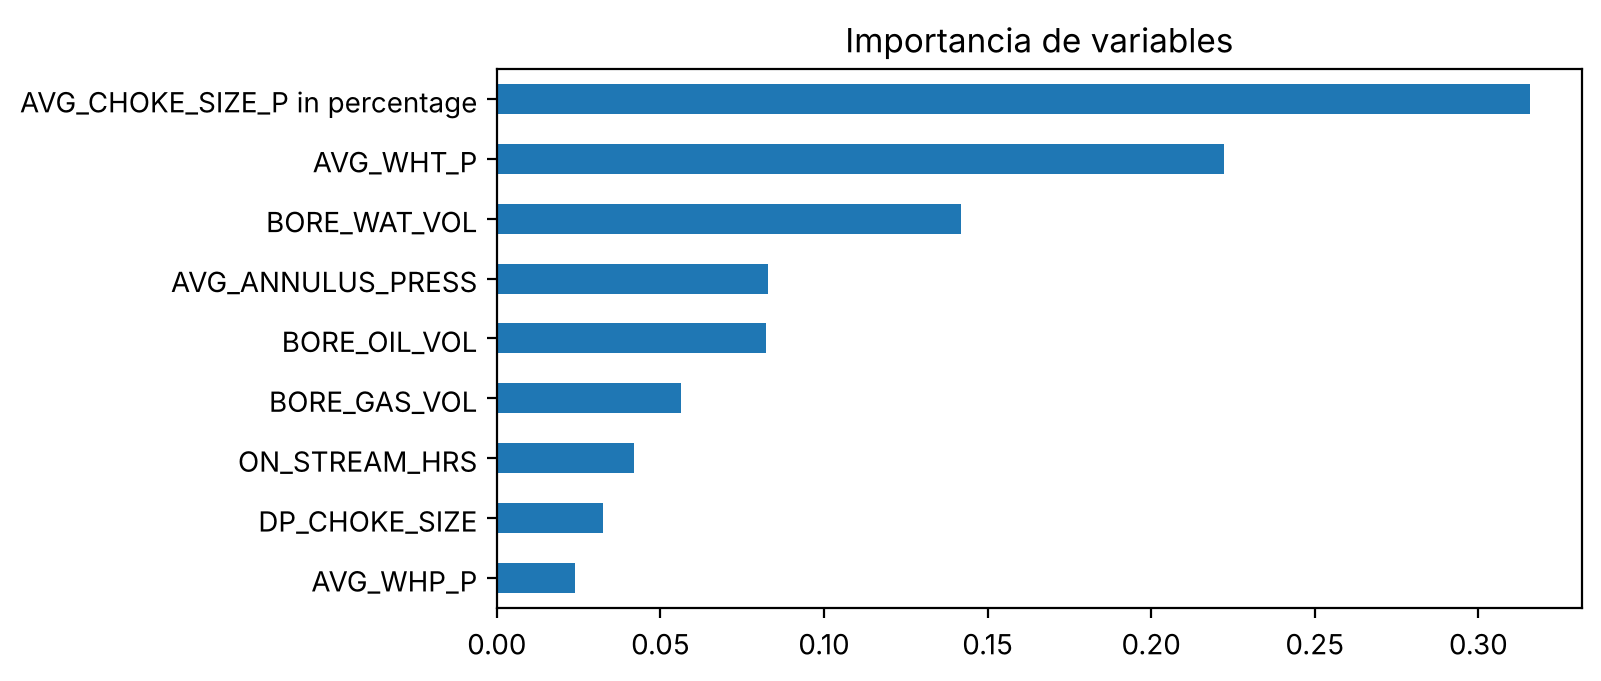

In [8]:
pd.Series(rf.feature_importances_, feats).sort_values().plot(kind='barh', figsize=(7,3.5), title='Importancia de variables');

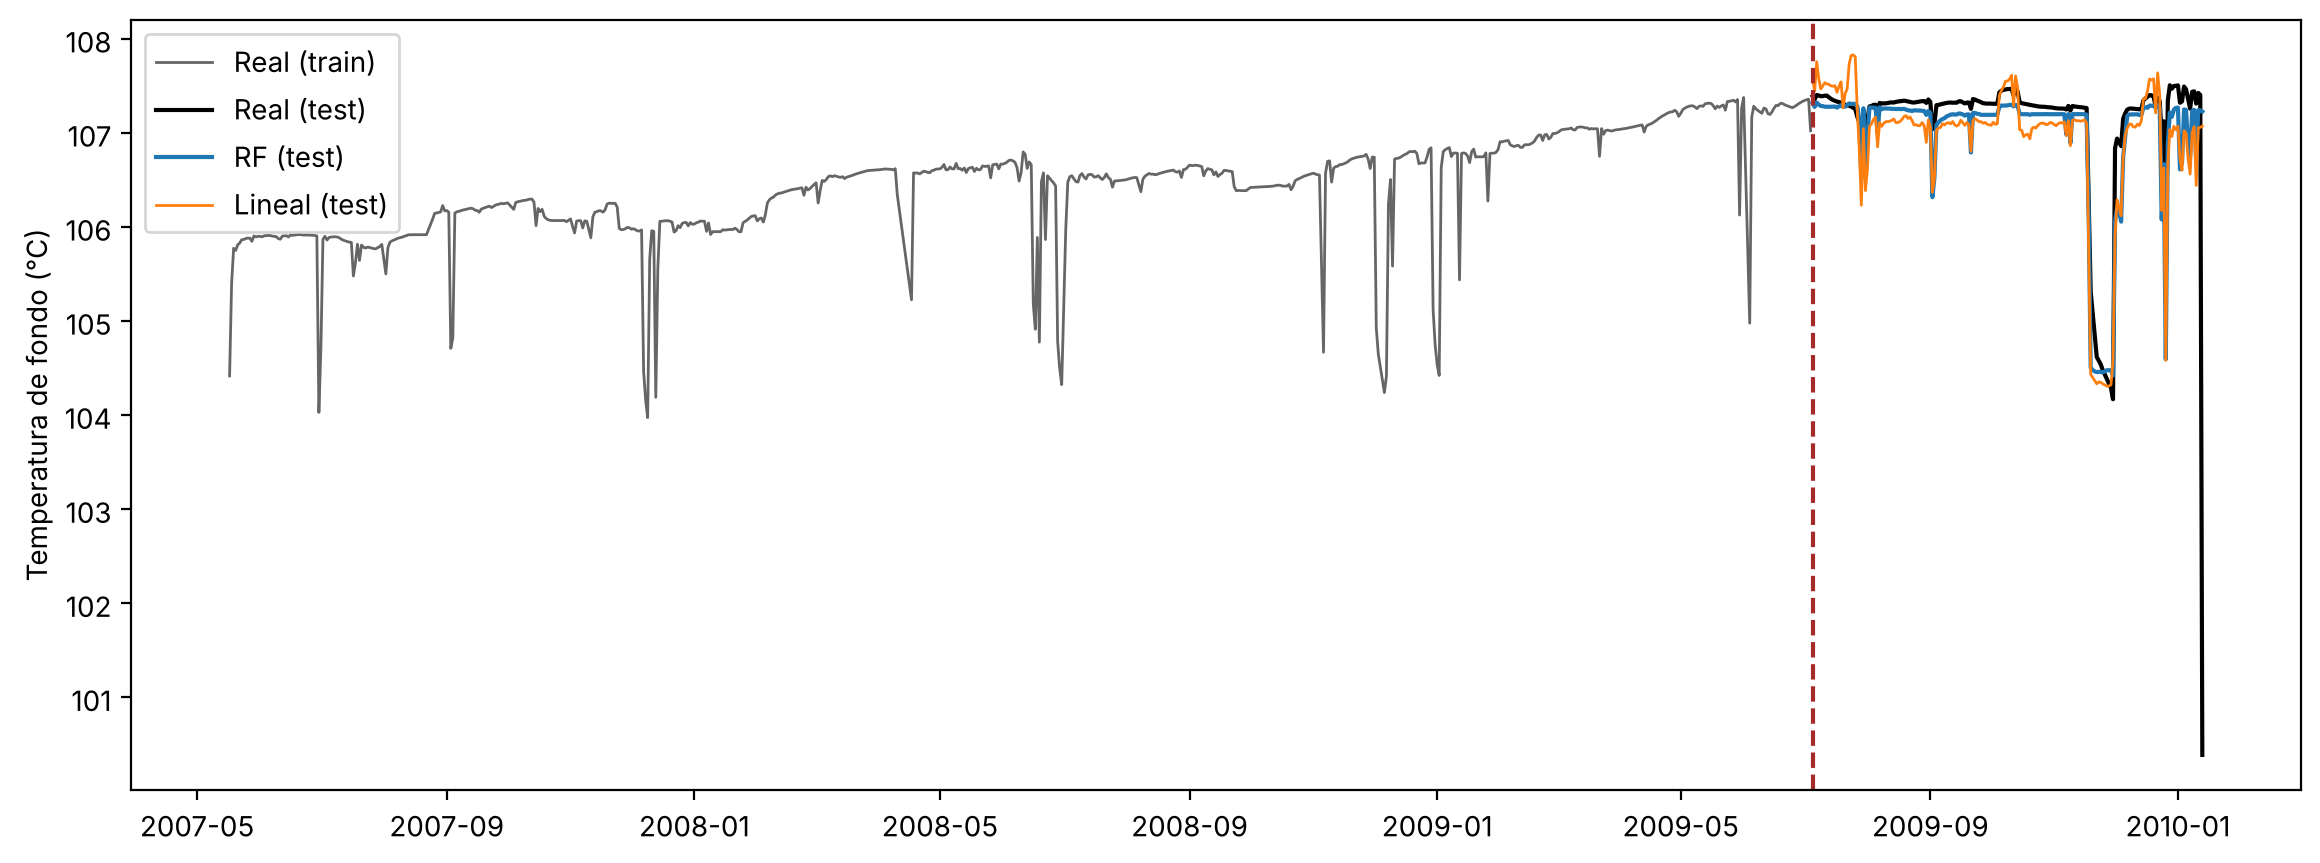

In [9]:
fig, ax = plt.subplots(figsize=(14,5))
ax.plot(tr.index, tr[out], color='0.4', lw=1, label='Real (train)')
ax.plot(te.index, te[out], color='k', lw=1.5, label='Real (test)')
ax.plot(te.index, p_rf, color='tab:blue', lw=1.5, label='RF (test)')
ax.plot(te.index, lr.predict(te[feats]), color='tab:orange', lw=1, label='Lineal (test)')
ax.axvline(te.index[0], color='brown', ls='--')
ax.set_ylabel('Temperatura de fondo (°C)'); ax.legend(); plt.show()  # sin ylim fijo: no ocultar errores

## 4. Aplicación: reconstrucción 2010–2016 (extrapolación, usar con cautela)

2010    107.20
2011    107.03
2012    107.04
2013    106.99
2014    106.70
2015    106.87
Name: T_estimada, dtype: float64


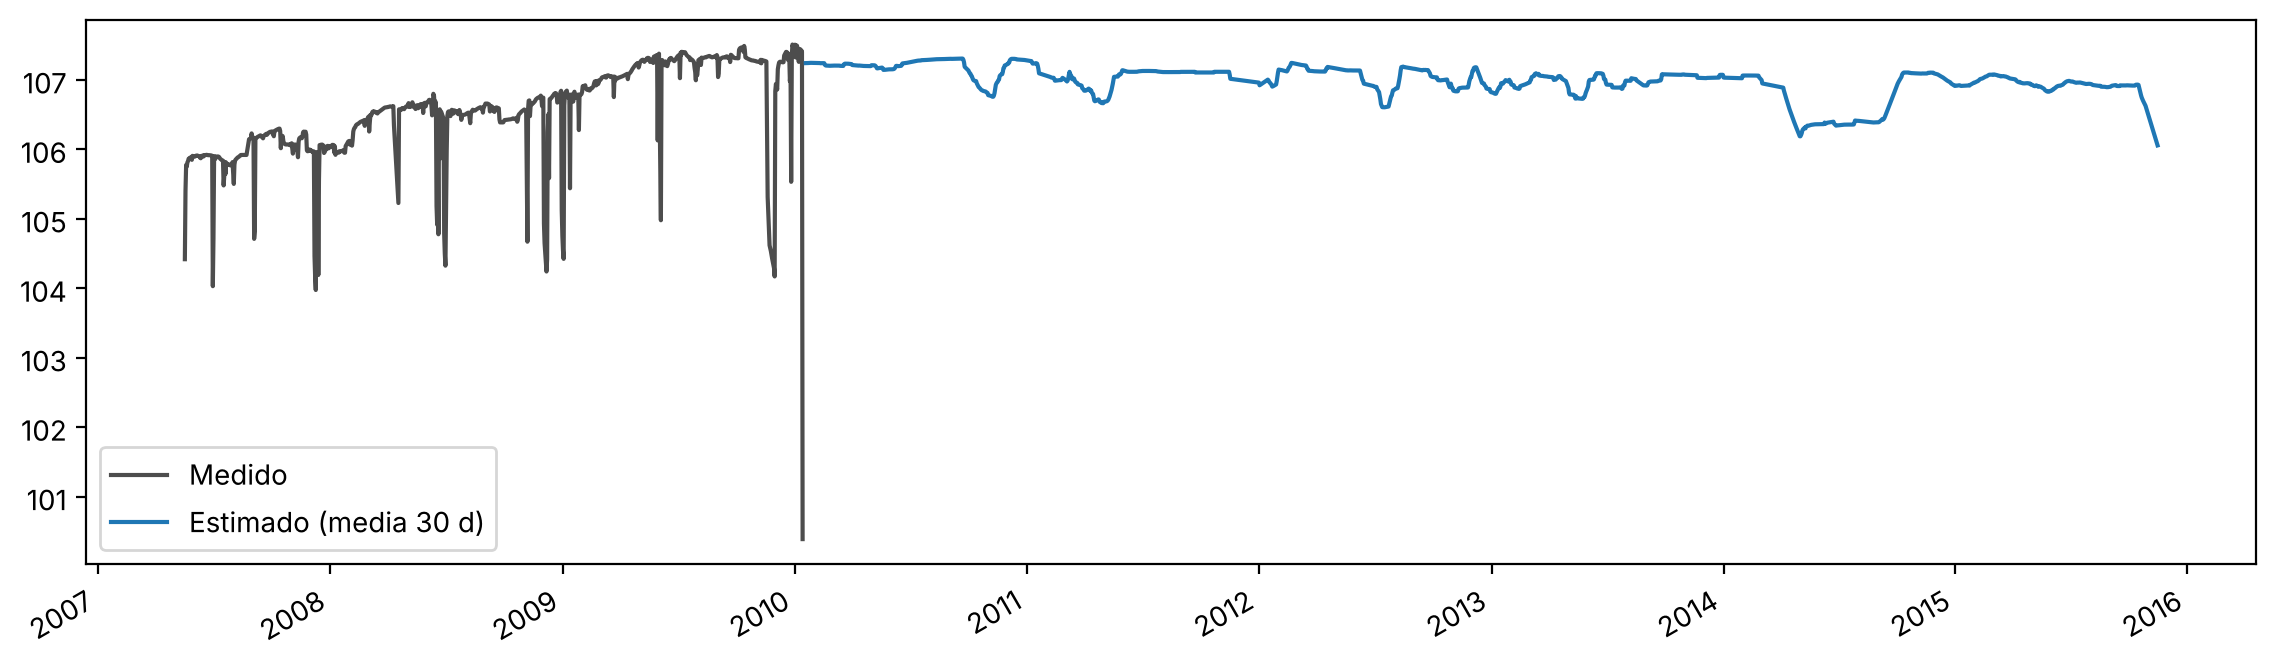

In [10]:
post = df[(df.index>valid.index.max()) & (df.ON_STREAM_HRS>0)]
post_pred = pd.Series(rf.predict(post[feats]), post.index, name='T_estimada')
print(post_pred.groupby(post_pred.index.year).mean().round(2))
ax = valid[out].plot(figsize=(14,4), color='0.3', label='Medido')
post_pred.rolling(30, min_periods=5).mean().plot(ax=ax, color='tab:blue', label='Estimado (media 30 d)'); ax.legend();